In [ ]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Loading the data set
df = pd.read_csv("/content/New_York.csv")

In [ ]:
#it reads the first five rows
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787.0,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149.0,1.0,9.0,2018-10-19,0.21,6.0,365.0
1,2595,Skylit Midtown Castle,2845.0,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225.0,1.0,45.0,2019-05-21,0.38,2.0,355.0
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632.0,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150.0,3.0,0.0,NaN,NaN,1.0,365.0
3,3831,Cozy Entire Floor of Brownstone,4869.0,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89.0,1.0,270.0,2019-07-05,4.64,1.0,194.0
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192.0,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80.0,10.0,9.0,2018-11-19,0.10,1.0,0.0


In [ ]:
#read last five rows
 df.tail()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
7335,5406187,Sunny Room by Prospect Park,400240.0,Murat,Brooklyn,Flatbush,40.65323,-73.96223,Private room,47.0,2.0,91.0,2019-07-07,1.73,2.0,51.0
7336,5409372,Artsy English Basement Apartment,7016520.0,Patricia,Brooklyn,Windsor Terrace,40.65497,-73.97459,Entire home/apt,120.0,2.0,17.0,2019-06-24,0.33,1.0,0.0
7337,5409607,SPACIOUS 2 Bedroom Apt Near Upper East HOSPITALS,25237492.0,Juliana,Manhattan,Upper East Side,40.76235,-73.96005,Entire home/apt,185.0,30.0,9.0,2018-12-07,0.18,34.0,342.0
7338,5410897,Fab Park Slope garden apt w/ patio,5768957.0,Michael,Brooklyn,South Slope,40.66832,-73.98754,Entire home/apt,169.0,30.0,136.0,2019-07-05,2.70,1.0,279.0
7339,5411,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
#check column information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7340 entries, 0 to 7339
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              7340 non-null   int64  
 1   name                            7332 non-null   object 
 2   host_id                         7339 non-null   float64
 3   host_name                       7334 non-null   object 
 4   neighbourhood_group             7339 non-null   object 
 5   neighbourhood                   7339 non-null   object 
 6   latitude                        7339 non-null   float64
 7   longitude                       7339 non-null   float64
 8   room_type                       7339 non-null   object 
 9   price                           7339 non-null   float64
 10  minimum_nights                  7339 non-null   float64
 11  number_of_reviews               7339 non-null   float64
 12  last_review                     65

In [ ]:
#check the dataset shapes
df.shape

(7340, 16)

In [ ]:
#check columns names
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [ ]:
#separate numerical and categorical columns
df.select_dtypes(include=np.number).columns

Index(['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights',
       'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365'],
      dtype='object')

In [ ]:
#separate numerical and categorical columns
df.select_dtypes(include='object').columns

Index(['name', 'host_name', 'neighbourhood_group', 'neighbourhood',
       'room_type', 'last_review'],
      dtype='object')

In [ ]:
#calculate missing value percentage

df.isnull().sum()/len(df)*100

,0
id,0.000000
name,0.108992
host_id,0.013624
host_name,0.081744
neighbourhood_group,0.013624
neighbourhood,0.013624
latitude,0.013624
longitude,0.013624
room_type,0.013624
price,0.013624


In [ ]:
df.isnull().sum()

,0
id,0
name,8
host_id,1
host_name,6
neighbourhood_group,1
neighbourhood,1
latitude,1
longitude,1
room_type,1
price,1


In [ ]:
#for data cleaning
df[['last_review','reviews_per_month','number_of_reviews']].isnull().sum()

,0
last_review,816
reviews_per_month,816
number_of_reviews,1


In [ ]:
#missing values
df[df['reviews_per_month'].isnull()][['number_of_reviews','reviews_per_month']]

,number_of_reviews,reviews_per_month
2,0.0,NaN
19,0.0,NaN
26,0.0,NaN
36,0.0,NaN
38,0.0,NaN
...,...,...
7299,0.0,NaN
7313,0.0,NaN
7314,0.0,NaN
7319,0.0,NaN


In [ ]:
#handle missing value
df['reviews_per_month']=df['reviews_per_month'].fillna(0)

In [ ]:
df['reviews_per_month'].isnull().sum()

np.int64(0)

In [ ]:
df['name'] = df['name'].fillna('Unknown')
df['host_name'] = df['host_name'].fillna('Unknown')
df['last_review'] = df['last_review'].fillna('Not Reviewed')
df['number_of_reviews'] = df['number_of_reviews'].fillna(0)

In [ ]:
df.isnull().sum()

,0
id,0
name,0
host_id,1
host_name,0
neighbourhood_group,1
neighbourhood,1
latitude,1
longitude,1
room_type,1
price,1


In [ ]:
#checking missing rows
df[df.isnull().any(axis=1)]

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
7339,5411,Unknown,NaN,Unknown,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,Not Reviewed,0.0,NaN,NaN


In [ ]:
df.loc[7339,df.loc[7339].isnull()]

,7339
host_id,NaN
neighbourhood_group,NaN
neighbourhood,NaN
latitude,NaN
longitude,NaN
room_type,NaN
price,NaN
minimum_nights,NaN
calculated_host_listings_count,NaN
availability_365,NaN


In [ ]:
df.loc[7339]

,7339
id,5411
name,Unknown
host_id,NaN
host_name,Unknown
neighbourhood_group,NaN
neighbourhood,NaN
latitude,NaN
longitude,NaN
room_type,NaN
price,NaN


In [ ]:
df=df.drop(index=7339)

In [ ]:
df.isnull().sum()

,0
id,0
name,0
host_id,0
host_name,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [ ]:
df.shape

(7339, 16)

In [ ]:
#removing irrelevant identifier columns
df=df.drop(['id','name','host_id','host_name','last_review'],axis=1)

In [ ]:
#updated dataset
df.head()

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,Kensington,40.64749,-73.97237,Private room,149.0,1.0,9.0,0.21,6.0,365.0
1,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225.0,1.0,45.0,0.38,2.0,355.0
2,Manhattan,Harlem,40.80902,-73.94190,Private room,150.0,3.0,0.0,0.00,1.0,365.0
3,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89.0,1.0,270.0,4.64,1.0,194.0
4,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80.0,10.0,9.0,0.10,1.0,0.0


In [ ]:
df.shape

(7339, 11)

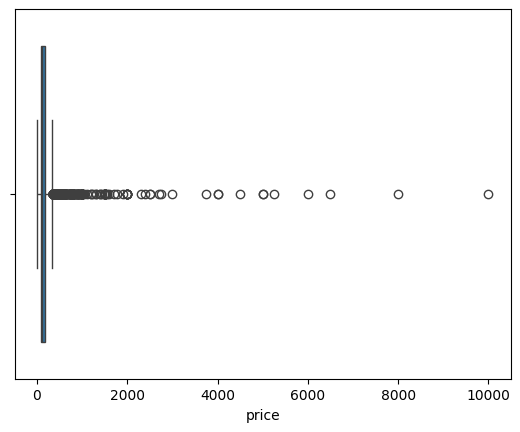

In [ ]:
#checking outlier in price
sns.boxplot(x=df['price'])
plt.show()

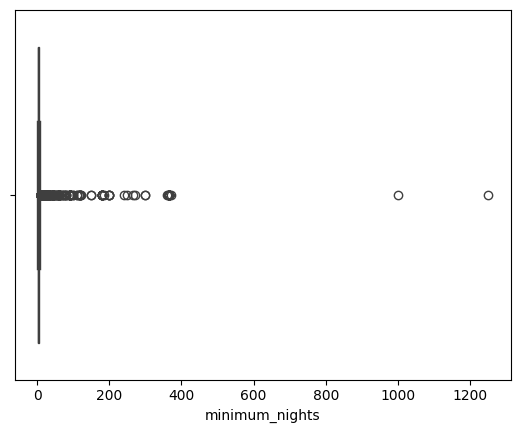

In [ ]:
#checking outlier in price
sns.boxplot(x=df['minimum_nights'])
plt.show()

In [ ]:
#handle outliers
df[['price','minimum_nights']].quantile(0.95)

,0.95
price,375.0
minimum_nights,30.0


In [ ]:
#remove extreme values
df = df[
    (df['price'] <= df['price'].quantile(0.95)) &
    (df['minimum_nights'] <= df['minimum_nights'].quantile(0.95))
]

In [ ]:
df.shape

(6830, 11)

In [ ]:
df.columns


Index(['neighbourhood_group', 'neighbourhood', 'latitude', 'longitude',
       'room_type', 'price', 'minimum_nights', 'number_of_reviews',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [ ]:
#dropping neighbourhood
df=df.drop('neighbourhood',axis=1)

In [ ]:
#hot encoding
df=pd.get_dummies(df,columns=['neighbourhood_group','room_type'],drop_first=True,dtype=int)

In [ ]:
#creating x and y
X=df.drop('price',axis=1)
y=df['price']

In [ ]:
#split the data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
#check shapes
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)


(5464, 13)
(1366, 13)
(5464,)
(1366,)


In [ ]:
#import and train the model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

model = LinearRegression()
model.fit(X_train, y_train)



LinearRegression()

In [ ]:
#predict price
y_pred = model.predict(X_test)

In [ ]:
#evaluate the model
print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score: 0.41972151343948627
MAE: 38.461882110698944
MSE: 2771.469867309852
RMSE: 52.64475156470825


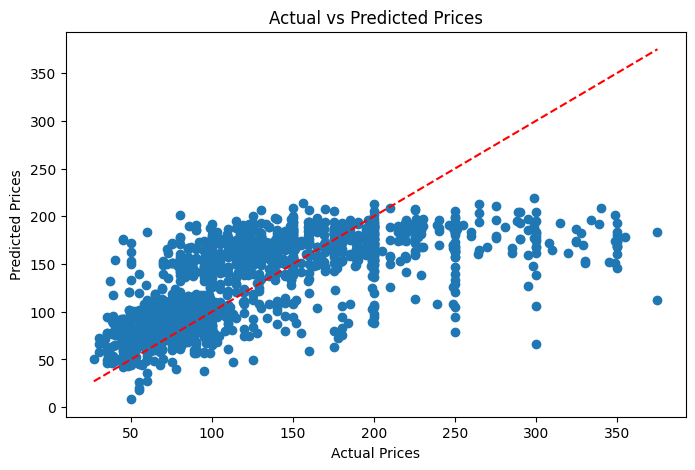

In [ ]:
#actual vs predicted price
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted Prices")
plt.show()

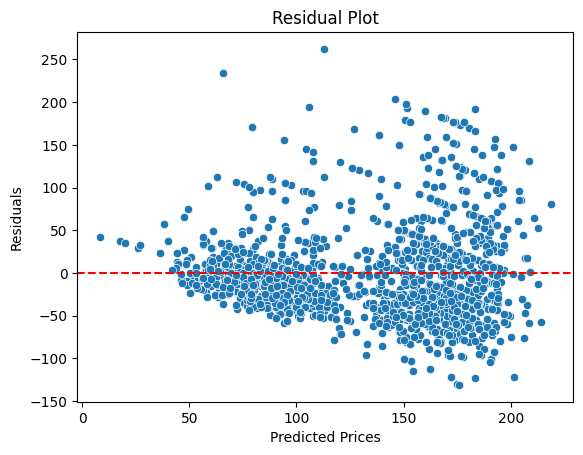

In [ ]:
#residual plot
residuals = y_test - y_pred

sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Predicted Prices")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()